# AutoFlow: demanda diaria y alertas para AutoMove City
## 1. Problema, alcance y datos
Caso académico: flota de 200 taxis autónomos en Bogotá. Interpolamos diez mediciones y agregamos (24,15) para cerrar el ciclo. No hay datos de viajes, zonas, disponibilidad ni tiempos de servicio: el prototipo genera una señal de demanda para apoyar el despacho, no optimiza rutas geográficas ni demuestra ahorros reales.

## 2. Modelo matemático
En cada intervalo $[t_i,t_{i+1}]$ usamos
$$S_i(t)=a_i+b_i(t-t_i)+c_i(t-t_i)^2+d_i(t-t_i)^3.$$
Se imponen interpolación en los extremos y continuidad de $S$, $S'$ y $S''$ en nodos interiores. Hay 10 polinomios y 40 coeficientes. Las 20 ecuaciones de interpolación, las 18 de continuidad de derivadas interiores y las 2 condiciones periódicas completan el sistema. La igualdad de valores en el cierre ya está impuesta por los datos.

Las fronteras son $S(0)=S(24)=15$, $S'(0)=S'(24)$ y $S''(0)=S''(24)$. Una spline natural fija las segundas derivadas extremas en cero, lo que no obliga a unir suavemente días sucesivos. Una frontera sujeta requeriría pendientes extremas conocidas, ausentes en el caso. La lineal presenta cambios de pendiente y el polinomio global de Lagrange depende de un grado alto. Las splines admiten nodos no equidistantes [1].

Para conectar con el cálculo manual, sea $M_i=S''(t_i)$ y $h_i=t_{i+1}-t_i$. En nodos interiores:
$$h_{i-1}M_{i-1}+2(h_{i-1}+h_i)M_i+h_iM_{i+1}=6\left(\frac{y_{i+1}-y_i}{h_i}-\frac{y_i-y_{i-1}}{h_{i-1}}\right).$$
Se cierra el sistema de forma cíclica, con $M_{10}=M_0$ y continuidad de pendiente entre el último y primer tramo. Luego:
$$a_i=y_i,\quad b_i=\frac{y_{i+1}-y_i}{h_i}-\frac{h_i(2M_i+M_{i+1})}{6},\quad c_i=\frac{M_i}{2},\quad d_i=\frac{M_{i+1}-M_i}{6h_i}.$$
SciPy resuelve este cálculo; la tabla de coeficientes permite reconstruir cada tramo.

## 3. Validación hold-out
Retiramos simultáneamente (9,120) y (18,98). Todos los métodos usan los mismos nodos restantes, incluido el cierre. Se calculan $RMSE=\sqrt{\frac1m\sum(\hat y-y)^2}$ y $E_{max}=\max|\hat y-y|$ sobre los dos puntos retirados. No evaluamos capacidad predictiva midiendo error en los nodos de ajuste. Lagrange usa representación baricéntrica del mismo polinomio global para estabilidad numérica.

## 4. Modelo final, umbral e integral
Después de validar se recuperan todos los datos. La grilla es $t_k=k/60$, $k=0,\ldots,1439$. Se identifican minutos con $S(t_k)>150$ y también las raíces continuas de $S(t)-150$. La integral $60\int_0^{24}S(t)dt$ aproxima solicitudes diarias: el factor 60 convierte horas en minutos. El umbral es una regla del caso y no una capacidad calculada a partir de los 200 taxis.

## 5. Mejora obligatoria: filtro causal a 30 minutos
La spline es una plantilla diaria conocida. Generamos observaciones sintéticas $z_k=\max(0,S(k/60)+r_k+g_k)$, con $r_k=0.95r_{k-1}+\epsilon_k$, $\epsilon_k\sim N(0,2^2)$, y $g_k=22\exp[-(k-560)^2/(2\,35^2)]$. La semilla es 42. El evento sólo lo ve el predictor a través de las observaciones disponibles.

Sobre el residuo observado $e_k=z_k-S(k/60)$ aplicamos:
$$L_k=\alpha e_k+(1-\alpha)L_{k-1},\qquad\alpha=0.25.$$
La media móvil ponderada $W_k$ usa hasta 15 residuos pasados y pesos 1,2,...,n, con más peso al reciente. El pronóstico es:
$$\hat z_{k+30|k}=\max\left(0,S((k+30)/60)+0.95^{30}\frac{L_k+W_k}{2}\right).$$
El factor de persistencia 0.95 coincide con el supuesto del escenario sintético y amortigua la corrección a 30 minutos. No fue estimado de datos reales. Como contraste, mantener la corrección completa empeora aquí el RMSE (8.3168 frente a 7.0051 de la base); por eso se documenta la reversión del residuo. Para producción se debe calibrar la persistencia con días históricos separados de prueba.

Se emite alerta si el pronóstico supera 150. No se utilizan observaciones futuras en $L_k$ ni $W_k$. Las métricas comparan el pronóstico emitido en k con la observación de k+30. Se evalúan 1410 pares del mismo día y se imprime un aviso al inicio de cada episodio. El CSV conserva todos los minutos con alerta.


In [ ]:
"""AutoFlow: interpolación diaria y alertas a 30 min. Ejecutar: python AutoFlow.py"""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline, BarycentricInterpolator

def ejecutar(salida="resultados", alpha=0.25, ventana=15, horizonte=30, semilla=42):
    salida = Path(salida)
    salida.mkdir(parents=True, exist_ok=True)
    t = np.array([0,1.5,3,6,9,12,15,18,19.5,21,24.])
    y = np.array([15,18,12,45,120,180,150,98,75,55,15.])
    pd.DataFrame({'hora': t, 'demanda': y}).to_csv(salida/'datos.csv', index=False)
    retenidos = np.isin(t, [9,18])
    xt, yt = t[~retenidos], y[~retenidos]
    xv, real = t[retenidos], y[retenidos]
    modelos = {
        'Spline periódica': CubicSpline(xt,yt,bc_type='periodic'),
        'Spline natural': CubicSpline(xt,yt,bc_type='natural'),
        'Lineal': lambda z: np.interp(z,xt,yt),
        'Lagrange global': BarycentricInterpolator(xt,yt)
    }
    filas, detalle = [], {'hora': xv, 'real': real}
    for nombre, modelo in modelos.items():
        pred = modelo(xv)
        detalle[nombre] = pred
        filas.append([nombre, float(np.sqrt(np.mean((pred-real)**2))), float(np.max(abs(pred-real)))])
    validacion = pd.DataFrame(filas, columns=['metodo','RMSE','error_maximo'])
    validacion.to_csv(salida/'validacion.csv',index=False)
    pd.DataFrame(detalle).to_csv(salida/'puntos_retirados.csv',index=False)
    s = CubicSpline(t,y,bc_type='periodic')
    natural = CubicSpline(t,y,bc_type='natural')
    lineal = lambda z: np.interp(z,t,y)
    minutos = np.arange(1440)
    horas = minutos/60
    base = s(horas)
    criticos = base > 150
    raices = s.solve(150, extrapolate=False)
    raices = np.unique(np.round(raices[(raices>=0)&(raices<=24)],10))
    bordes = np.r_[0,raices,24]
    intervalos = [[float(a),float(b)] for a,b in zip(bordes[:-1],bordes[1:]) if s((a+b)/2)>150]
    grupos = np.split(minutos[criticos], np.where(np.diff(minutos[criticos])>1)[0]+1)
    hhmm = lambda m: f'{int(m)//60:02d}:{int(m)%60:02d}'
    rangos = [{'inicio': hhmm(g[0]),'fin': hhmm(g[-1]),'minutos':len(g)} for g in grupos if len(g)]
    pd.DataFrame({'minuto':minutos,'hora':horas,'demanda_spline':base,'demanda_natural':natural(horas),'supera_150':criticos}).to_csv(salida/'demanda_1440_minutos.csv',index=False)
    pd.DataFrame({'inicio':t[:-1],'fin':t[1:],'a':s.c[3],'b':s.c[2],'c':s.c[1],'d':s.c[0]}).to_csv(salida/'coeficientes.csv',index=False)

    # Simulación reproducible. Los parámetros son supuestos de demostración.
    # La curva del caso es una plantilla diaria conocida; las observaciones son sintéticas.
    rng = np.random.default_rng(semilla)
    residuo = np.zeros(1440)
    for k in range(1,1440):
        residuo[k] = 0.95*residuo[k-1] + rng.normal(0,2)
    evento = 22*np.exp(-0.5*((minutos-560)/35)**2)
    observada = np.maximum(0,base+residuo+evento)
    residual_observado = observada-base
    suavizado = np.zeros(1440)
    ponderada = np.zeros(1440)
    suavizado[0] = residual_observado[0]
    for k in range(1440):
        if k:
            suavizado[k] = alpha*residual_observado[k]+(1-alpha)*suavizado[k-1]
        historial = residual_observado[max(0,k-ventana+1):k+1]
        pesos = np.arange(1,len(historial)+1)
        ponderada[k] = np.average(historial,weights=pesos)
    # Pronóstico emitido en k para k+H. Sólo se usan residuos hasta k.
    origen = np.arange(1440-horizonte)
    objetivo = origen+horizonte
    correccion = (0.95**horizonte)*(0.5*suavizado[origen]+0.5*ponderada[origen])
    pronostico = np.maximum(0,s(objetivo/60)+correccion)
    referencia = s(objetivo/60)
    verdad = observada[objetivo]
    alerta = pronostico>150
    tp = int(np.sum(alerta & (verdad>150)))
    fp = int(np.sum(alerta & (verdad<=150)))
    fn = int(np.sum(~alerta & (verdad>150)))
    tn = int(np.sum(~alerta & (verdad<=150)))
    alertas = pd.DataFrame({'minuto_emision':origen,'hora_emision':[hhmm(k) for k in origen],'minuto_objetivo':objetivo,'hora_objetivo':[hhmm(k) for k in objetivo],'pronostico_30min':pronostico,'observada_objetivo_sintetica':verdad,'alerta':alerta})
    alertas.to_csv(salida/'pronosticos_y_alertas.csv',index=False)
    pd.DataFrame({'minuto':minutos,'observada_sintetica':observada,'base':base,'residuo_SE':suavizado,'residuo_MMP':ponderada}).to_csv(salida/'simulacion.csv',index=False)
    # Episodios: imprimir una alerta al inicio de cada racha, evitando 1 mensaje/minuto.
    inicios = np.flatnonzero(alerta & np.r_[True,~alerta[:-1]])
    for k in inicios:
        print(f'ALERTA {hhmm(k)}: demanda prevista para {hhmm(k+horizonte)} = {pronostico[k]:.2f} solicitudes/min')
    resultados = {
        'RMSE_validacion': dict(zip(validacion.metodo,validacion.RMSE)),
        'reduccion_RMSE_porcentaje':float(100*(1-validacion.RMSE.iloc[0]/validacion.RMSE.iloc[2])),
        'raices_umbral_horas':raices.tolist(),'intervalos_continuos_abiertos':intervalos,
        'rangos_minutos_criticos':rangos,'minutos_criticos':int(criticos.sum()),
        'solicitudes_diarias_integral':float(60*s.integrate(0,24)),
        'minimo_base':float(base.min()),
        'filtro_simulado':{'semilla':semilla,'alpha':alpha,'ventana':ventana,'horizonte':horizonte,'persistencia_residuo':0.95,
            'RMSE_base':float(np.sqrt(np.mean((referencia-verdad)**2))),
            'RMSE_filtro':float(np.sqrt(np.mean((pronostico-verdad)**2))),
            'TP':tp,'FP':fp,'FN':fn,'TN':tn,
            'precision':tp/(tp+fp) if tp+fp else 0,
            'recall':tp/(tp+fn) if tp+fn else 0,
            'episodios_alerta':int(len(inicios))},
        'frontera':{'valor_0':float(s(0)),'valor_24':float(s(24)),
            'derivada_0':float(s(0,1)),'derivada_24':float(s(24,1)),
            'segunda_0':float(s(0,2)),'segunda_24':float(s(24,2))}}
    (salida/'resumen.json').write_text(json.dumps(resultados,indent=2,ensure_ascii=False))

    plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
    def terminar(nombre):
        plt.tight_layout(); plt.savefig(salida/nombre,dpi=180); plt.close()
    plt.figure(figsize=(10,4.3))
    plt.plot(horas,base,label='Spline periódica',color='#007f82')
    plt.plot(horas,natural(horas),'--',label='Spline natural',color='#e39b39')
    plt.plot(horas,lineal(horas),':',label='Lineal',color='#65758a')
    plt.scatter(t,y,c='#12263a',s=22,zorder=3,label='Datos y cierre')
    plt.axhline(150,color='#bb4050',ls='--',label='Umbral 150')
    plt.fill_between(horas,0,base,where=criticos,color='#007f82',alpha=.13)
    plt.xlabel('Hora del día'); plt.ylabel('Solicitudes/min'); plt.legend(ncol=2,fontsize=9)
    terminar('curvas.png')
    plt.figure(figsize=(10,4.3))
    for nombre in ['Spline periódica','Lineal']:
        plt.plot(horas,modelos[nombre](horas),label=nombre)
    plt.scatter(xt,yt,c='black',s=20,label='Entrenamiento')
    plt.scatter(xv,real,c='#bb4050',marker='x',s=100,label='Datos retirados')
    plt.xlabel('Hora'); plt.ylabel('Solicitudes/min'); plt.legend(fontsize=9)
    terminar('validacion.png')
    plt.figure(figsize=(10,4.3))
    plt.plot(horas,observada,color='#b7c1ce',lw=.8,label='Observada sintética')
    plt.plot(horas,base,color='#65758a',ls='--',label='Base periódica')
    plt.plot(objetivo/60,pronostico,color='#007f82',label='Pronóstico emitido 30 min antes')
    plt.axhline(150,color='#bb4050',ls='--',label='Umbral')
    plt.scatter(objetivo[alerta][::12]/60,pronostico[alerta][::12],c='#bb4050',s=12)
    plt.xlabel('Hora objetivo'); plt.ylabel('Solicitudes/min'); plt.legend(fontsize=8)
    terminar('filtro.png')
    # Comprobaciones de consistencia numérica y de separación de validación.
    assert len(base)==1440 and not np.any(np.isin(xt,[9,18]))
    assert np.allclose(s(t),y,atol=1e-9)
    assert all(np.isclose(s(0,k),s(24,k)) for k in range(3))
    assert tp+fp+fn+tn==1440-horizonte
    assert np.all(objetivo-origen==horizonte)
    print(validacion.round(4).to_string(index=False))
    print(json.dumps(resultados,ensure_ascii=False,indent=2))
    return resultados


resultados = ejecutar()

ALERTA 09:29: demanda prevista para 09:59 = 150.10 solicitudes/min
          metodo   RMSE  error_maximo
Spline periódica 4.8362        6.8275
  Spline natural 4.7443        6.7058
          Lineal 5.4886        7.5000
 Lagrange global 8.6184       11.9566
{
  "RMSE_validacion": {
    "Spline periódica": 4.836196916330326,
    "Spline natural": 4.744263585459401,
    "Lineal": 5.488624600025037,
    "Lagrange global": 8.618391348162426
  },
  "reduccion_RMSE_porcentaje": 11.886906670420416,
  "raices_umbral_horas": [
    10.1391550713,
    15.0
  ],
  "intervalos_continuos_abiertos": [
    [
      10.1391550713,
      15.0
    ]
  ],
  "rangos_minutos_criticos": [
    {
      "inicio": "10:09",
      "fin": "14:59",
      "minutos": 291
    }
  ],
  "minutos_criticos": 291,
  "solicitudes_diarias_integral": 121823.78906249999,
  "minimo_base": 11.855194365270808,
  "filtro_simulado": {
    "semilla": 42,
    "alpha": 0.25,
    "ventana": 15,
    "horizonte": 30,
    "persistencia_resid

## 6. Gráficas y tablas generadas
Los resultados siguientes se calculan al ejecutar el cuaderno.

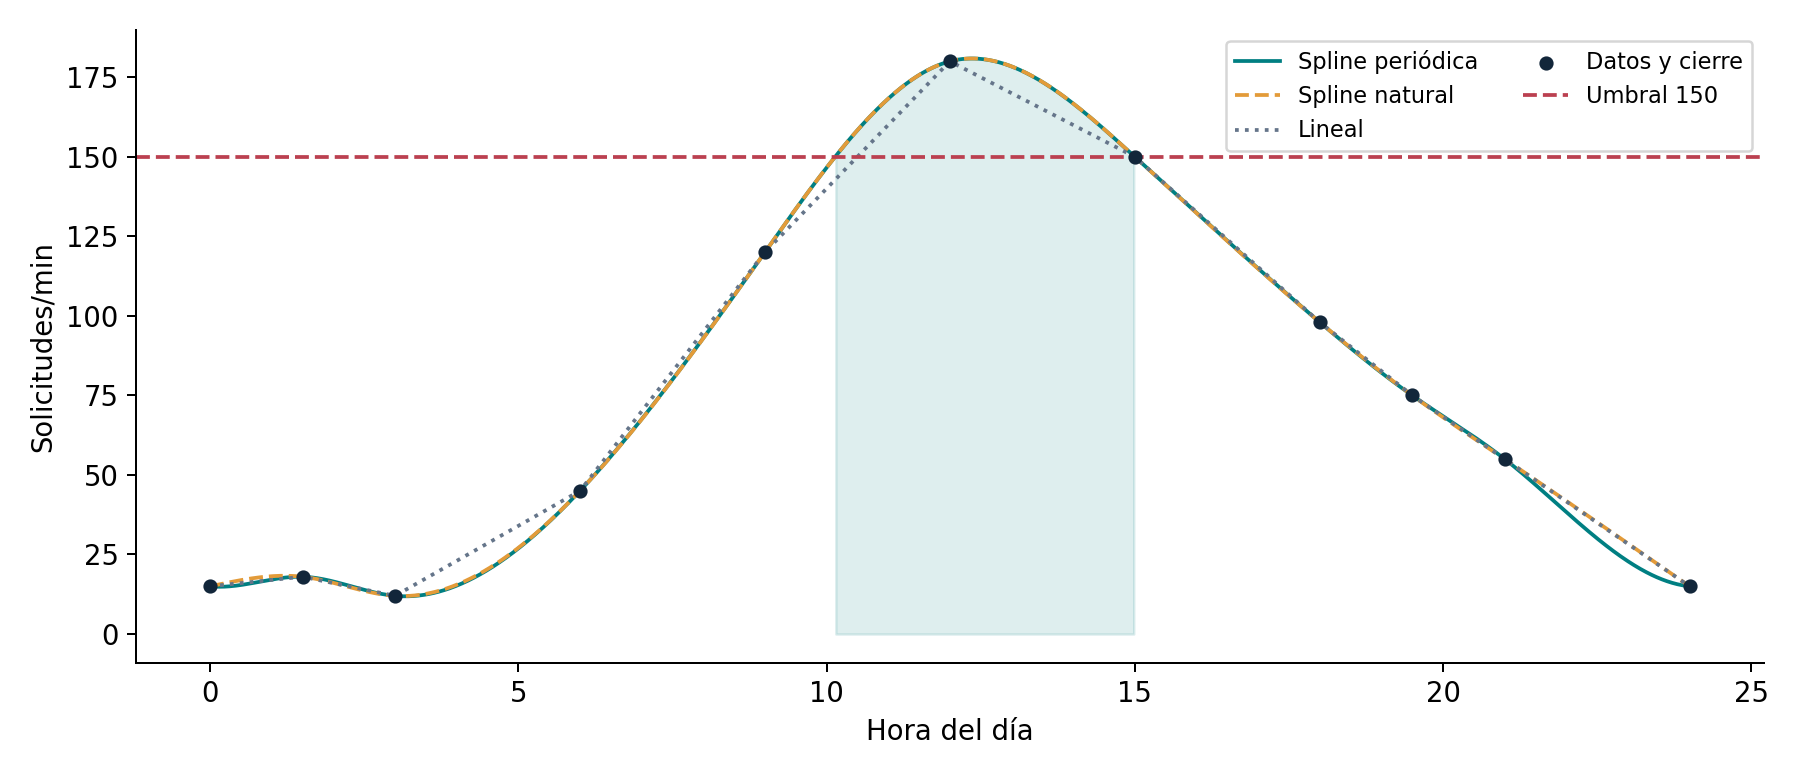

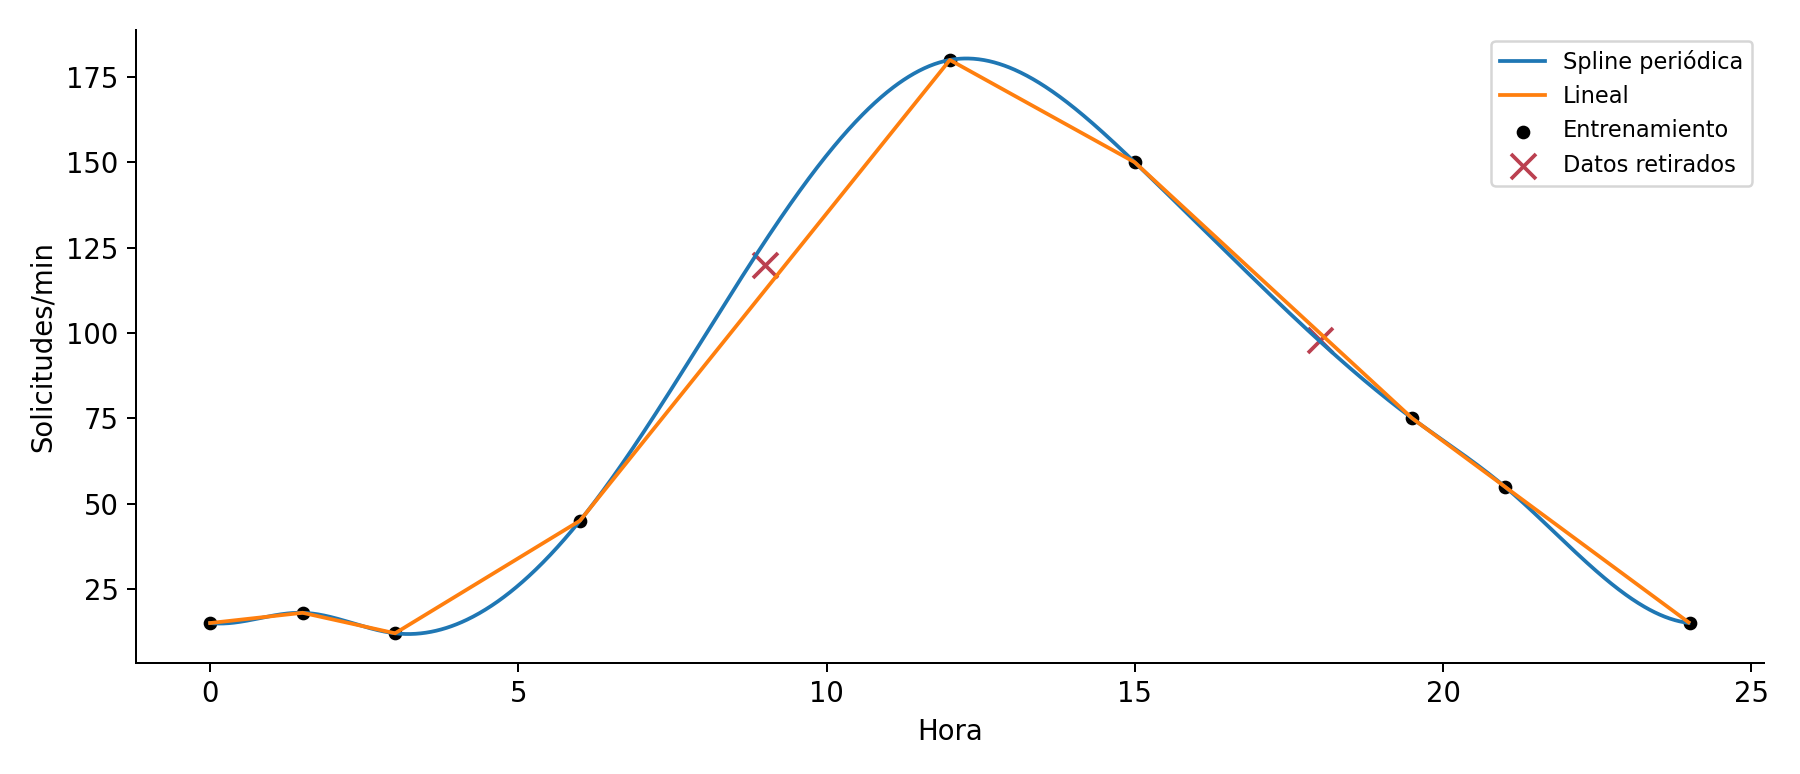

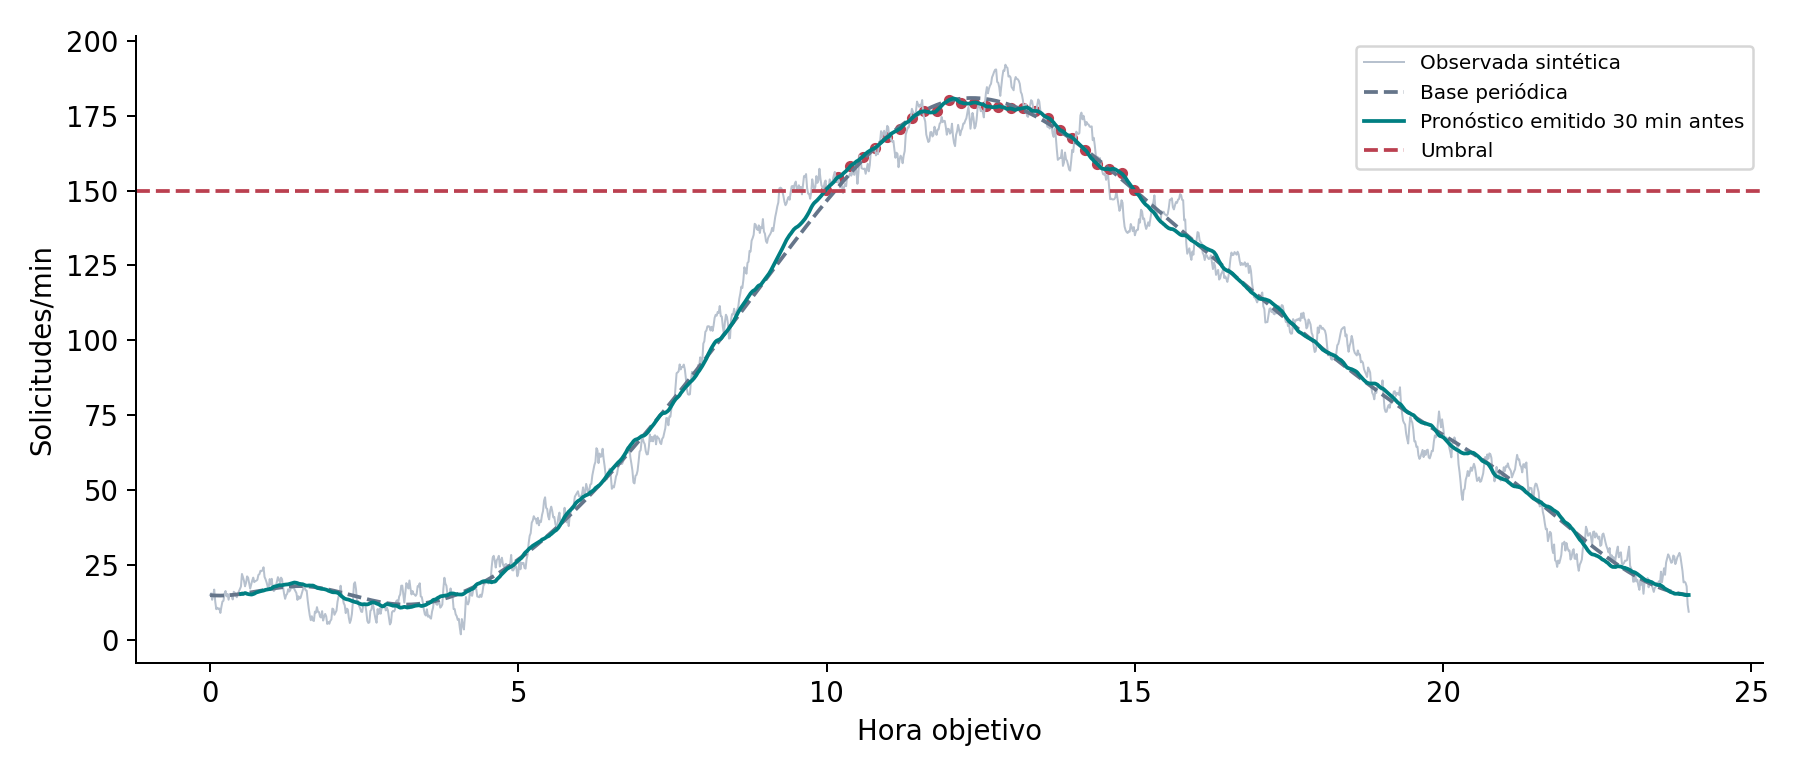

,metodo,RMSE,error_maximo
0,Spline periódica,4.8362,6.8275
1,Spline natural,4.7443,6.7058
2,Lineal,5.4886,7.5000
3,Lagrange global,8.6184,11.9566


,hora,real,Spline periódica,Spline natural,Lineal,Lagrange global
0,9.0,120.0,126.8275,126.7058,112.5,131.9566
1,18.0,98.0,97.5958,98.2211,100.0,95.6351


,inicio,fin,a,b,c,d
0,0.0,1.5,15.0,-1.9495,6.9841,-2.9008
1,1.5,3.0,18.0,-0.5773,-6.0694,2.5250
2,3.0,6.0,12.0,-1.7414,5.2933,-0.3487
3,6.0,9.0,45.0,20.6028,2.1547,-0.2297
4,9.0,12.0,120.0,27.3302,0.0877,-0.8437
5,12.0,15.0,180.0,5.0763,-7.5057,0.8268
6,15.0,18.0,150.0,-17.6355,-0.0649,0.0552
7,18.0,19.5,98.0,-16.5343,0.4319,0.2458
8,19.5,21.0,75.0,-13.5792,1.5381,-0.9161
9,21.0,24.0,55.0,-15.1487,-2.5844,1.0632


In [ ]:
from IPython.display import display, Image
for nombre in ['curvas.png','validacion.png','filtro.png']:
    display(Image(filename='resultados/'+nombre))
for nombre in ['validacion.csv','puntos_retirados.csv','coeficientes.csv']:
    display(pd.read_csv('resultados/'+nombre).round(4))

## 7. Arquitectura y estrategia
Flujo: datos del caso → cierre diario → spline periódica → curva base. En paralelo, observaciones por minuto → residuo → suavizado exponencial y media móvil ponderada → corrección amortiguada. Ambos llegan al pronóstico a 30 minutos → umbral → alerta al operador → decisión de despacho → registro de KPIs.

Nombre comercial: **AutoFlow**. Propuesta: módulo de apoyo al despacho que estima demanda minuto a minuto y anticipa sobrecarga. Cliente: AutoMove City. Modelo comercial propuesto: implementación inicial y suscripción por flota con monitoreo y soporte. El piloto no requiere inventar precios ni inversión.

La meta de reducir la espera 20% requiere comparar tiempos reales antes y después. KPI: 100*(espera_base-espera_piloto)/espera_base. Ahorro de combustible: 100*(litros_base-litros_piloto)/litros_base para viajes y condiciones comparables. ROI: 100*(beneficio-costo)/costo, con beneficio medido y costo total. No hay datos para calcular estos tres resultados en este taller.

## 8. Conclusiones y límites
La spline periódica mejora el RMSE frente a lineal 11.89% en sólo dos puntos retirados. La natural obtiene un error ligeramente menor, pero no satisface la continuidad periódica requerida. La curva base supera 150 de 10:09 a 14:59 en la grilla de minutos. Las métricas del filtro dependen del escenario sintético y no equivalen a desempeño operativo. El siguiente paso es un piloto con varios días, zonas, oferta de taxis y tiempos de viaje. La periodicidad asumida y sólo diez mediciones limitan la generalización.

## Referencias
[1] SciPy. CubicSpline. https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html
[2] NumPy. numpy.interp. https://numpy.org/doc/stable/reference/generated/numpy.interp.html
[3] statsmodels. Exponential smoothing. https://www.statsmodels.org/stable/examples/notebooks/generated/exponential_smoothing.html

## 9. Demo interactiva para la defensa
Ejecuta esta celda y mueve el selector de minuto de emisión. La demanda observada objetivo se muestra sólo para evaluar después el pronóstico; el filtro no la utiliza al emitirlo.

In [ ]:
import pandas as pd
from pathlib import Path

def demo(minuto=569):
    tabla = pd.read_csv(Path('resultados') / 'pronosticos_y_alertas.csv')
    fila = tabla.iloc[int(minuto)]
    print(f"Emisión: {fila['hora_emision']} | Objetivo: {fila['hora_objetivo']}")
    print(f"Pronóstico: {fila['pronostico_30min']:.2f} solicitudes/min")
    print('ALERTA: prever refuerzo de oferta' if fila['alerta'] else 'SIN ALERTA')
    print(f"Observación sintética posterior: {fila['observada_objetivo_sintetica']:.2f}")

try:
    from ipywidgets import interact, IntSlider
    interact(demo, minuto=IntSlider(value=569, min=0, max=1409, step=1, description='Minuto'))
except ImportError:
    demo(569)
    print('Para activar el selector instala ipywidgets y vuelve a ejecutar esta celda.')


Emisión: 09:29 | Objetivo: 09:59
Pronóstico: 150.10 solicitudes/min
ALERTA: prever refuerzo de oferta
Observación sintética posterior: 153.36
Para activar el selector instala ipywidgets y vuelve a ejecutar esta celda.
